# 制造解时间收敛：保存数据重绘

比较普通 SDIRK2/3 与对应 mr-ccSAV 格式在同一 MAC 网格上的时间误差。精确参照为网格相容的半离散制造解，不是连续外力的空间收敛实验。

本 Notebook 只读取显式选定的报告数值表及其原始成员校验信息，不构造模型、不推进方程、不调用分析器，也不写入原始记录或正式报告。图表使用**已有误差表**，不声称重新计算了场误差。

环境与正文片段见本目录 README。已有输出可直接预览；重新执行需要项目数据。输入缺失时请补回原始记录，不要自动换用最新批次。

In [1]:
from pathlib import Path

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'pyproject.toml').is_file() and (p / 'experiments').is_dir())
REPORT_DIRECTORY = Path('reports/manufactured_ns_convergence/20260926T100547-ac5f1fac')
# 更换报告时须明确核实并同步这些摘要，不能在读取后自动接受新摘要。
EXPECTED_ANALYSIS_SHA256 = '2345e4c9fba94f5e4412e79341d0253cf5cae9b624b060d917304139d963e56d'
EXPECTED_TABLE_SHA256 = '614694012d982357179fe756f6a64df5af97555684fd316745e0c08cc59d83c0'

In [2]:
import csv
import json
import math
import sys
import h5py

sys.path.insert(0, str(PROJECT_ROOT))
from experiments.workflow import digest, load_record

if REPORT_DIRECTORY.is_absolute():
    raise ValueError('REPORT_DIRECTORY must be project-relative')
report = PROJECT_ROOT / REPORT_DIRECTORY
analysis_path, table_path = report / 'analysis.json', report / 'tables/errors.csv'
for path, expected in ((analysis_path, EXPECTED_ANALYSIS_SHA256), (table_path, EXPECTED_TABLE_SHA256)):
    if digest(path) != expected:
        raise ValueError(f'Presentation input checksum mismatch: {path}')
analysis = json.loads(analysis_path.read_text())
if analysis['status'] != 'complete':
    raise ValueError('Complete analysis report required')
# 分析器捕获的是分析当时的批次快照；之后 runner 会更新原批次的状态和报告位置。
# 校验原报告声明的快照，不能拿已变化的原 batch.json 冒充分析输入。
batch_path = report / 'input_batch.json'
if digest(batch_path) != analysis['batch_sha256']:
    raise ValueError('Captured batch checksum mismatch')
batch = json.loads(batch_path.read_text())
config = batch['config']
base = config['base']
if base['experiment'] != 'manufactured_ns':
    raise ValueError('Expected the MAC manufactured temporal study')
SCHEMES = ('sdirk2', 'sdirk2_mrsav', 'sdirk3', 'sdirk3_mrsav')
expected_members = {(k, name) for k in config['k_levels'] for name in SCHEMES}
with table_path.open(newline='') as stream:
    rows = list(csv.DictReader(stream))
by_key = {(int(row['k']), row['scheme']): row for row in rows}
members = {(member['k'], member['scheme']): member for member in batch['members']}
if (len(rows) != len(expected_members) or set(by_key) != expected_members
        or len(batch['members']) != len(expected_members) or set(members) != expected_members):
    raise ValueError('Incomplete or duplicate comparison members')
inputs = {Path(item['path']).name: item['sha256'] for item in analysis['inputs']}
if len(inputs) != len(expected_members) or len(analysis['inputs']) != len(inputs):
    raise ValueError('Incomplete or duplicate analysis inputs')
solver_source = batch['source']['code_sha256']
for key, row in by_key.items():
    member = members[key]
    run_id = Path(member['path']).name
    if Path(row['run']).name != run_id:
        raise ValueError('Table and batch identify different runs')
    # 原记录可能含旧机器的绝对路径。按明确的 experiment/run-id 定位，绝不搜索最新记录。
    run = PROJECT_ROOT / 'runs/manufactured_ns' / run_id
    saved, manifest = load_record(run)
    with h5py.File(run / 'results.h5', 'r') as data:
        endpoint = float(data['final/t'][()])
        if data.attrs.get('status') != manifest['status'] or not math.isfinite(endpoint):
            raise ValueError(f'Incompatible HDF5 status/endpoint: {run_id}')
        if manifest['status'] == 'complete' and not math.isclose(endpoint, base['T'], rel_tol=1e-9, abs_tol=1e-12):
            raise ValueError(f'Completed run has the wrong endpoint: {run_id}')
    if (manifest['source']['code_sha256'] != solver_source
            or manifest['status'] != row['status'] or member['status'] != row['status']
            or inputs.get(run_id) != manifest['results_sha256']
            or row['results_sha256'] != manifest['results_sha256']):
        raise ValueError(f'Incompatible saved source/status/checksum: {run_id}')
    if (saved['scheme'] != row['scheme'] or any(saved.get(k) != v for k, v in base.items())
            or not math.isclose(saved['dt'], config['tau_base'] * 2.**(-key[0]), rel_tol=1e-12)
            or not math.isclose(float(row['dt']), saved['dt'], rel_tol=1e-12)):
        raise ValueError(f'Run/config mismatch: {run_id}')
    for field in ('L2', 'H1'):
        value = float(row[field])
        if row['status'] == 'complete' and (not math.isfinite(value) or value < 0):
            raise ValueError(f'Invalid completed error: {run_id}/{field}')
        if row['status'] != 'complete' and not math.isnan(value):
            raise ValueError(f'Failed run must not carry a valid endpoint error: {run_id}')
        row[field] = value
        row[field + '_rate'] = float(row[field + '_rate'])
    row['k'], row['dt'] = key[0], float(row['dt'])
rows = sorted(rows, key=lambda row: (SCHEMES.index(row['scheme']), row['k']))
print('Study: MAC-consistent manufactured temporal convergence')
print('Explicit report:', REPORT_DIRECTORY)
print('Captured batch:', Path(analysis['batch']).parent.name, '| snapshot status:', batch['status'])
print('Verified saved members:', len(rows), '| complete:', sum(row['status'] == 'complete' for row in rows))
print('Saved solver source:', solver_source)
print('Saved analysis source:', analysis['source']['code_sha256'])
print('Analysis SHA256:', EXPECTED_ANALYSIS_SHA256)
print('Derived table SHA256:', EXPECTED_TABLE_SHA256)
print('Parameters:', json.dumps(base, ensure_ascii=False, sort_keys=True))
print('Error definition:', analysis['error_definition'])
print('Integrity checks are not a new convergence proof or a recomputation of field errors.')

Study: MAC-consistent manufactured temporal convergence
Explicit report: reports/manufactured_ns_convergence/20260926T100547-ac5f1fac
Captured batch: 20260926T094814-5097bbbb | snapshot status: running
Verified saved members: 40 | complete: 40
Saved solver source: 8111dbcad17bb7e31123e3508d342c3b44a62a4aa629c8003d036e109e4c8f37
Saved analysis source: 8111dbcad17bb7e31123e3508d342c3b44a62a4aa629c8003d036e109e4c8f37
Analysis SHA256: 2345e4c9fba94f5e4412e79341d0253cf5cae9b624b060d917304139d963e56d
Derived table SHA256: 614694012d982357179fe756f6a64df5af97555684fd316745e0c08cc59d83c0
Parameters: {"T": 2.0, "amplitude": 0.05, "experiment": "manufactured_ns", "gamma": 1.0, "log_every": 1000, "lx": 1.0, "ly": 1.0, "nu": 0.01, "nx": 128, "ny": 128, "snapshots": [2.0], "stokes_tolerance": 1e-09}
Error definition: MAC-consistent discrete manufactured velocity, p=0; L2 and K-based H1 seminorm
Integrity checks are not a new convergence proof or a recomputation of field errors.


In [3]:
from html import escape
from IPython.display import HTML, display

columns = ('scheme', 'k', 'dt', 'status', 'L2', 'L2_rate', 'H1', 'H1_rate')
body = []
for row in rows:
    cells = [f'{row[name]:.3e}' if isinstance(row[name], float) else str(row[name]) for name in columns]
    body.append('<tr>' + ''.join('<td>' + escape(value) + '</td>' for value in cells) + '</tr>')
display(HTML('<table><caption>Saved absolute errors and adjacent rates (not recomputed)</caption>'
             + '<thead><tr>' + ''.join('<th>' + escape(name) + '</th>' for name in columns)
             + '</tr></thead><tbody>' + ''.join(body) + '</tbody></table>'))

scheme,k,dt,status,L2,L2_rate,H1,H1_rate
sdirk2,-1,2.000e-01,complete,7.654e-05,nan,9.733e-04,nan
sdirk2,0,1.000e-01,complete,1.823e-05,2.070e+00,2.321e-04,2.068e+00
sdirk2,1,5.000e-02,complete,4.450e-06,2.034e+00,5.676e-05,2.032e+00
sdirk2,2,2.500e-02,complete,1.100e-06,2.017e+00,1.405e-05,2.014e+00
sdirk2,3,1.250e-02,complete,2.733e-07,2.008e+00,3.500e-06,2.005e+00
sdirk2,4,6.250e-03,complete,6.813e-08,2.004e+00,8.740e-07,2.001e+00
sdirk2,5,3.125e-03,complete,1.701e-08,2.002e+00,2.185e-07,2.000e+00
sdirk2,6,1.563e-03,complete,4.249e-09,2.001e+00,5.464e-08,2.000e+00
sdirk2,7,7.813e-04,complete,1.062e-09,2.001e+00,1.366e-08,2.000e+00
sdirk2,8,3.906e-04,complete,2.654e-10,2.000e+00,3.416e-09,2.000e+00


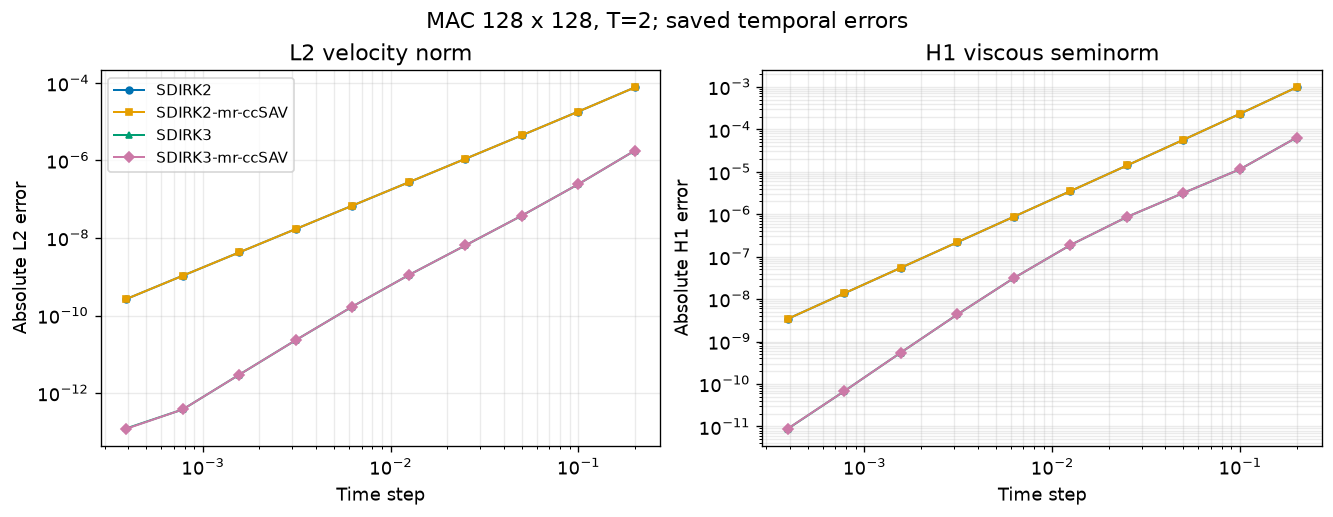

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

labels = ('SDIRK2', 'SDIRK2-mr-ccSAV', 'SDIRK3', 'SDIRK3-mr-ccSAV')
colors = ('#0072B2', '#E69F00', '#009E73', '#CC79A7')
with plt.rc_context({'font.size': 11, 'figure.dpi': 120}):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
    for name, label, color, marker in zip(SCHEMES, labels, colors, ('o', 's', '^', 'D')):
        group = [row for row in rows if row['scheme'] == name]
        for axis, norm in zip(axes, ('L2', 'H1')):
            values = [row[norm] if row['status'] == 'complete' and row[norm] > 0 else float('nan')
                      for row in group]
            axis.loglog([row['dt'] for row in group], values, label=label, color=color,
                        marker=marker, markersize=4, linewidth=1.2)
            axis.set(xlabel='Time step', ylabel='Absolute ' + norm + ' error',
                     title=norm + (' velocity norm' if norm == 'L2' else ' viscous seminorm'))
            axis.grid(True, which='both', alpha=.25)
    axes[0].legend(fontsize=9)
    fig.suptitle(f'MAC {base["nx"]} x {base["ny"]}, T={base["T"]:g}; saved temporal errors')
    display(fig)
    plt.close(fig)

## 如何解释

表格给出原报告的绝对速度误差及相邻层观察阶，图中保留全部步长，不裁掉粗步或细步误差平台。H1 指离散粘性算子定义的半范数，不是压力误差。失败成员不参与有效终点误差曲线；零误差或非正值不能画在对数轴上，仍可在表格中查看状态。

图表验证的是固定空间网格的时间误差行为，不证明空间收敛、无滑移 PDE 三阶理论或长期稳定性。完整性校验只确认记录之间的对应关系。原报告数值表的摘要在参数单元中固定，其误差未由本 Notebook 重算。当前源码不必等于历史源码，但同一比较内的保存成员必须满足原有来源一致性。

若整个项目迁移，保留 reports 与 runs 的相对布局即可；若数据没有随项目复制，已有输出仍可阅读，重新执行会明确失败，不会自动补算。